In [1]:
import random
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif

os.environ["PYTHONHASHSEED"] = "42"
np.random.seed(42)
random.seed(42)
print("Seed: 42")


Seed: 42


In [2]:
DATA_PATH = "data/cleveland.csv"
COLUMNS =["age","sex","cp","trestbps","chol","fbs","restecg","thalach",
          "exang","oldpeak","slope","ca","thal","target"]

raw = pd.read_csv(DATA_PATH, header = None)
raw.columns = COLUMNS
print(raw.info())
print()
print("Shape:", raw.shape)
print()

print('Display dataframe:')
display(raw.head())

print('Checking missing value:')
display(raw.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB
None

Shape: (303, 14)

Display dataframe:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Checking missing value:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

In [3]:
numeric_cols = ["age","trestbps","chol","thalach","oldpeak"]
categorical_cols = ["sex","cp","fbs","restecg","exang","slope","ca","thal"]


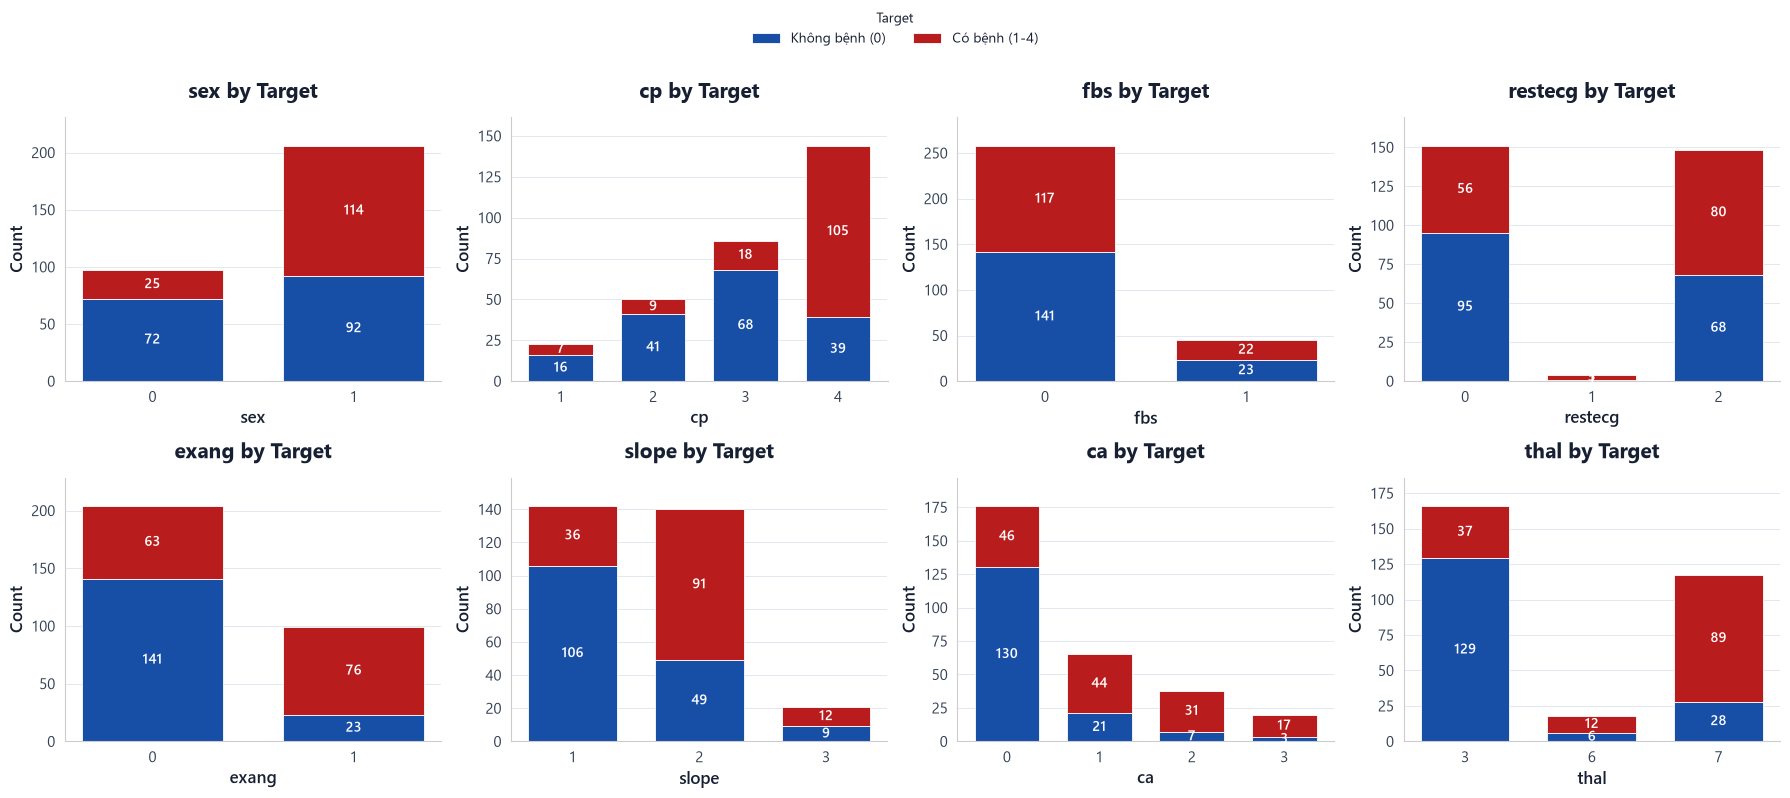

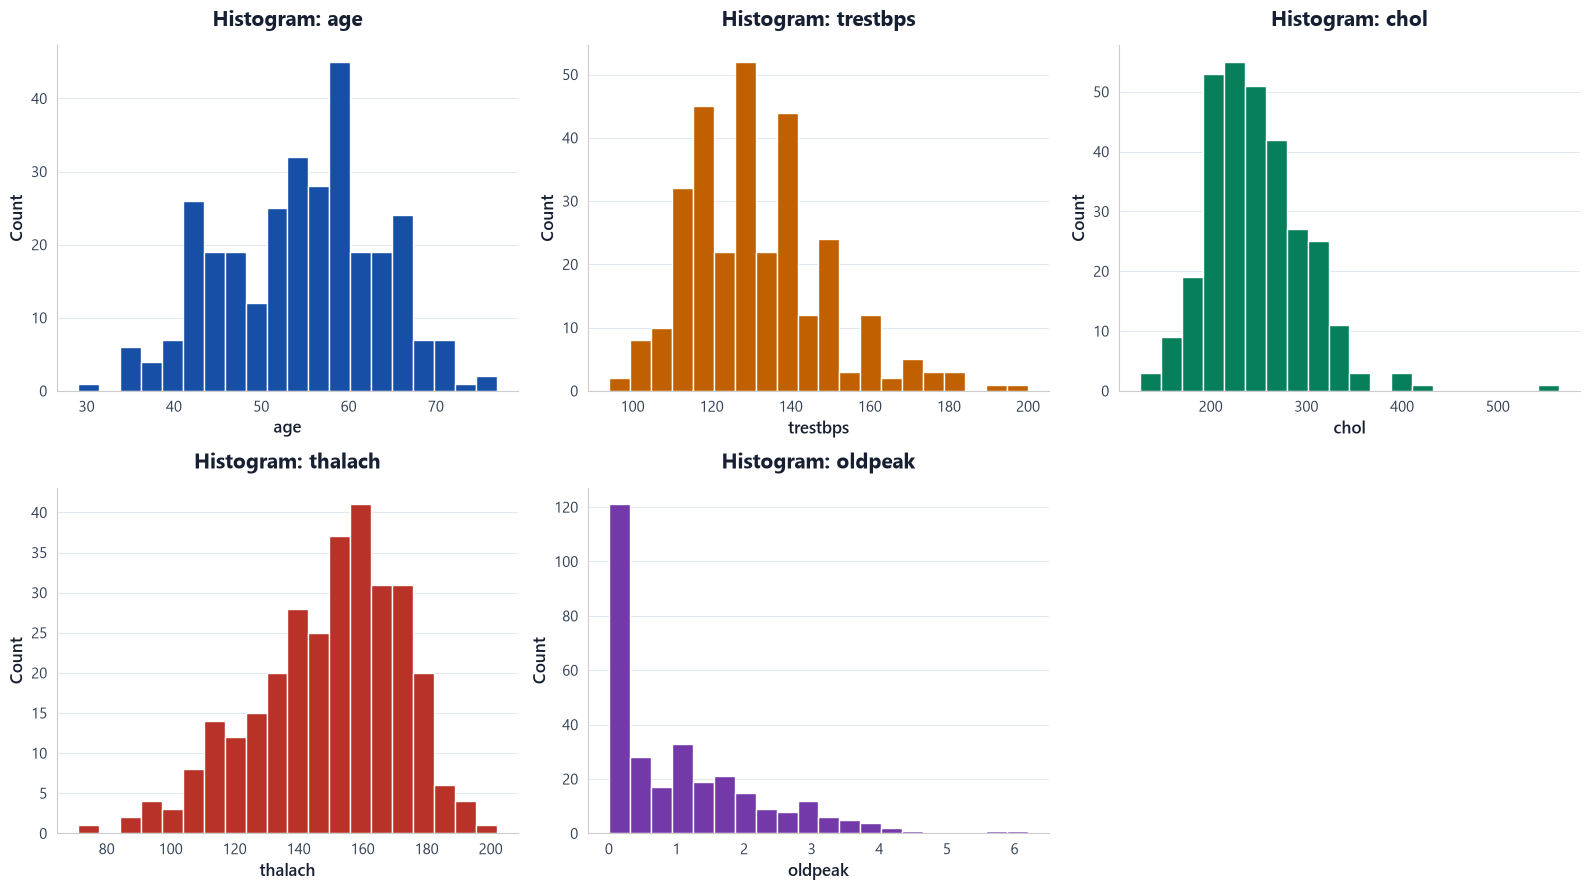

In [4]:

# Prepare a separate dataframe for plotting; keep raw unchanged.
plot_data = raw[categorical_cols + numeric_cols].apply(pd.to_numeric, errors="coerce")
plot_colors = ["#174EA6", "#B83227", "#087F5B", "#7439A8",
               "#C06000", "#007C91", "#A32562", "#3949AB"]
plot_style = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "axes.labelsize": 12,
    "axes.labelweight": "semibold",
    "text.color": "#172033",
    "axes.labelcolor": "#172033",
    "xtick.color": "#334155",
    "ytick.color": "#334155",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "grid.color": "#E2E8F0",
    "grid.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}

# Stack categorical counts by binary disease status without changing raw.
count_target = pd.to_numeric(raw["target"], errors="coerce").map({
    0: "Không bệnh (0)",
    1: "Có bệnh (1-4)", 2: "Có bệnh (1-4)",
    3: "Có bệnh (1-4)", 4: "Có bệnh (1-4)",
})
count_target_order = ["Không bệnh (0)", "Có bệnh (1-4)"]
count_target_colors = ["#174EA6", "#B91C1C"]

with sns.axes_style("whitegrid"), plt.rc_context(plot_style):
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, col in zip(axes.flat, categorical_cols):
        levels = sorted(plot_data[col].dropna().unique())
        counts = pd.crosstab(plot_data[col], count_target).reindex(
            index=levels, columns=count_target_order, fill_value=0
        )
        positions = np.arange(len(levels))
        bottom = np.zeros(len(levels))
        for label, color in zip(count_target_order, count_target_colors):
            values = counts[label].to_numpy()
            bars = ax.bar(positions, values, bottom=bottom, label=label,
                          color=color, width=0.7, edgecolor="white", linewidth=0.6)
            ax.bar_label(bars, labels=[str(v) if v > 0 else "" for v in values],
                         label_type="center", color="white", fontsize=10,
                         fontweight="semibold")
            bottom += values
        ax.set_xticks(positions, [f"{level:g}" for level in levels])
        ax.set_title(f"{col} by Target")
        ax.set_xlabel(col)
        ax.set_ylabel("Count")
        ax.grid(axis="x", visible=False)
        ax.set_axisbelow(True)
        ax.margins(y=0.12)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Target", loc="upper center",
               ncol=2, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    histogram_colors = ["#174EA6", "#C06000", "#087F5B", "#B83227", "#7439A8"]
    for ax, col, color in zip(axes.flat, numeric_cols, histogram_colors):
        sns.histplot(data=plot_data, x=col, bins=20, color=color,
                     edgecolor="white", alpha=1, ax=ax)
        ax.set_title(f"Histogram: {col}")
        ax.set_ylabel("Count")
        ax.grid(axis="x", visible=False)
        ax.set_axisbelow(True)
    for ax in axes.flat[len(numeric_cols):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


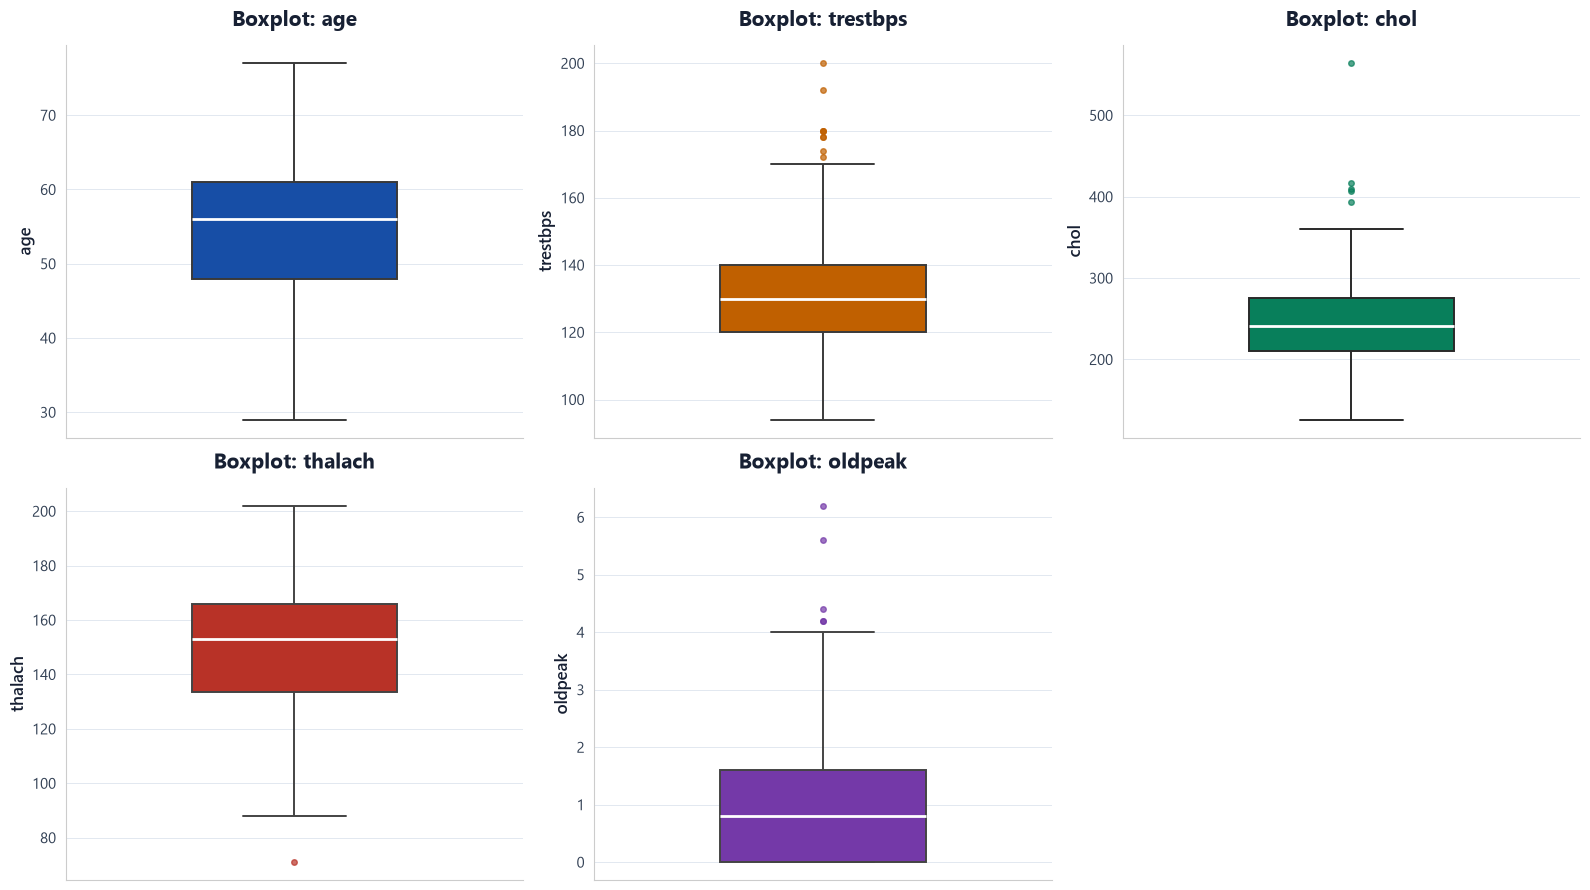

In [5]:
# Boxplots for numeric features
with sns.axes_style("whitegrid"), plt.rc_context(plot_style):
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    boxplot_colors = ["#174EA6", "#C06000", "#087F5B", "#B83227", "#7439A8"]
    for ax, col, color in zip(axes.flat, numeric_cols, boxplot_colors):
        sns.boxplot(data=plot_data, y=col, color=color, saturation=1,
                    width=0.45, linewidth=1.4,
                    medianprops={"color": "white", "linewidth": 2},
                    flierprops={"marker": "o", "markersize": 4,
                                "markerfacecolor": color,
                                "markeredgecolor": color, "alpha": 0.7},
                    ax=ax)
        ax.set_title(f"Boxplot: {col}")
        ax.set_ylabel(col)
        ax.grid(axis="x", visible=False)
        ax.set_axisbelow(True)
    for ax in axes.flat[len(numeric_cols):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


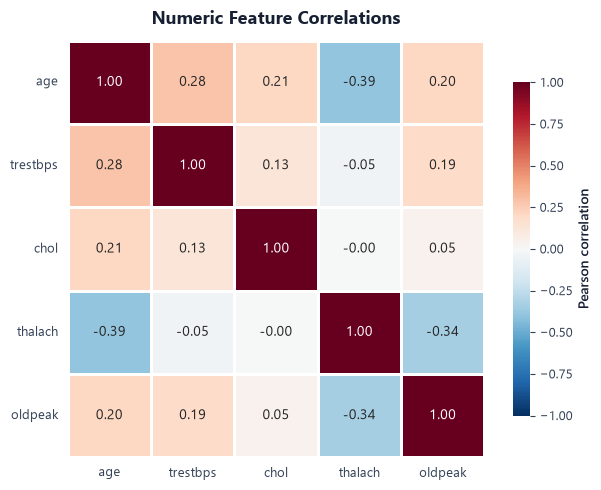

In [6]:
# Pearson correlation matrix for numeric features
numeric_corr = raw[numeric_cols].apply(pd.to_numeric, errors="coerce").corr(method="pearson")

with sns.axes_style("white"), plt.rc_context(plot_style):
    fig, ax = plt.subplots(figsize=(6.5, 5))
    sns.heatmap(numeric_corr, annot=True, fmt=".2f",
                cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                square=True, linewidths=1, linecolor="white",
                annot_kws={"size": 10, "weight": "normal"},
                cbar_kws={"label": "Pearson correlation", "shrink": 0.8},
                ax=ax)
    ax.set_title("Numeric Feature Correlations", fontsize=13, pad=12)
    ax.tick_params(axis="x", rotation=0, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=9)
    ax.collections[0].colorbar.ax.tick_params(labelsize=9)
    ax.collections[0].colorbar.set_label("Pearson correlation", fontsize=10)
    fig.tight_layout()
    plt.show()


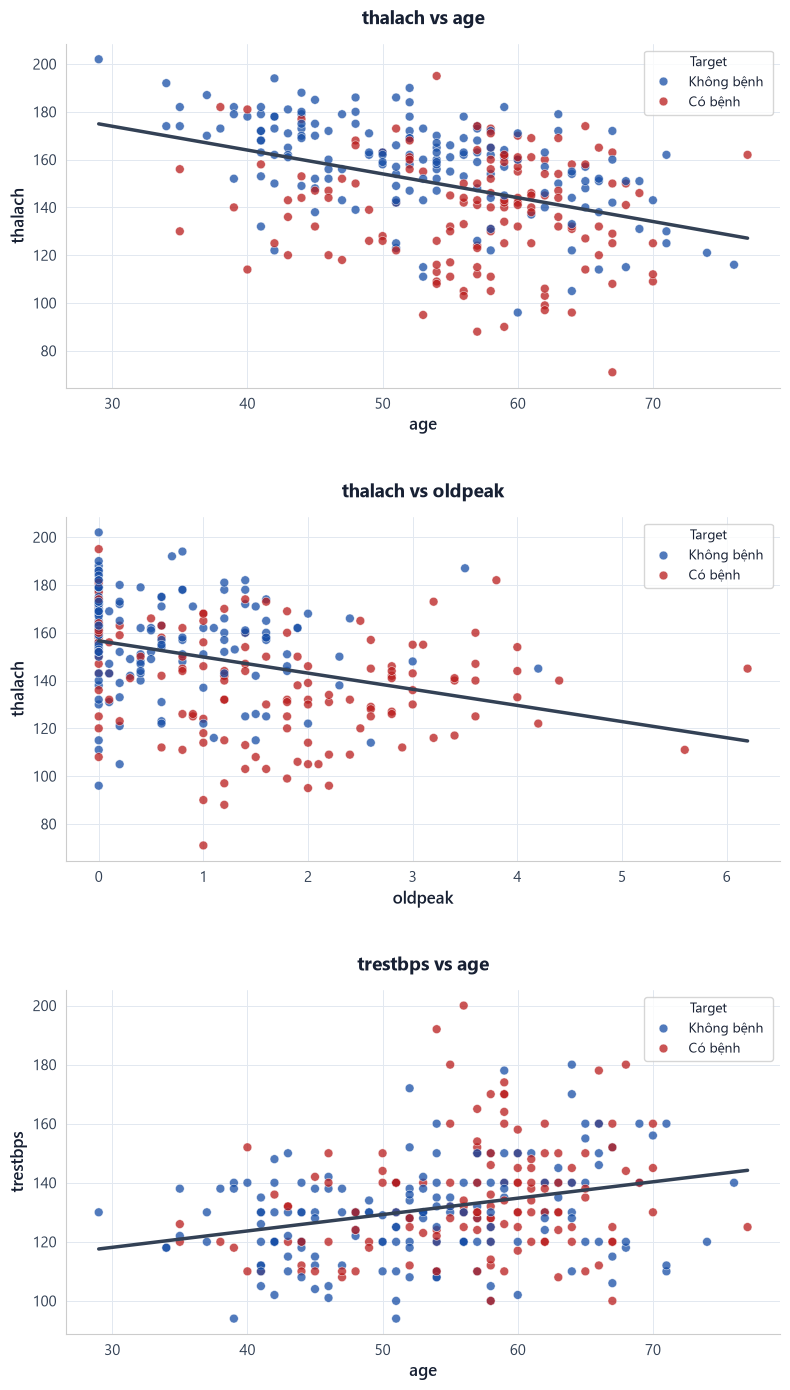

In [7]:
# Scatter plots grouped by disease status, with overall regression lines
regression_pairs = [
    ("age", "thalach"),
    ("oldpeak", "thalach"),
    ("age", "trestbps"),
]
disease_labels = {0: "Không bệnh ", 1: "Có bệnh ",
                  2: "Có bệnh ", 3: "Có bệnh ", 4: "Có bệnh "}
disease_order = [disease_labels[0], disease_labels[1]]
disease_palette = {disease_order[0]: "#174EA6", disease_order[1]: "#B91C1C"}

with sns.axes_style("whitegrid"), plt.rc_context(plot_style):
    fig, axes = plt.subplots(3, 1, figsize=(8, 14))
    for ax, (x_col, y_col) in zip(axes, regression_pairs):
        pair_data = raw[[x_col, y_col, "target"]].apply(pd.to_numeric, errors="coerce")
        pair_data["disease_status"] = pair_data["target"].map(disease_labels)
        pair_data = pair_data.dropna(subset=[x_col, y_col, "disease_status"])
        sns.scatterplot(data=pair_data, x=x_col, y=y_col,
                        hue="disease_status", hue_order=disease_order,
                        palette=disease_palette, s=40, alpha=0.75,
                        edgecolor="white", linewidth=0.4, ax=ax)
        sns.regplot(data=pair_data, x=x_col, y=y_col, scatter=False, ci=None,
                    line_kws={"color": "#334155", "linewidth": 2.5}, ax=ax)
        ax.set_title(f"{y_col} vs {x_col}", fontsize=14)
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.legend(title="Target")
        ax.set_axisbelow(True)
    fig.tight_layout(h_pad=3.5)
    plt.show()


In [8]:
# Keep raw unchanged; export binary diagnosis targets (0 = no disease, 1 = disease).
feature_cols = [col for col in raw.columns if col != "target"]
X = raw[feature_cols].apply(pd.to_numeric, errors="coerce")
y = (pd.to_numeric(raw["target"], errors="raise") > 0).astype(int)

# Split before fitting any preprocessing steps; preserve class proportions.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, random_state=42, stratify=y_holdout
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", MinMaxScaler()),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Fit on train only; retain numeric-then-categorical column order from the reference.
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

train_df = X_train_processed.assign(target=y_train)
val_df = X_val_processed.assign(target=y_val)
test_df = X_test_processed.assign(target=y_test)

# With 303 rows, rounding gives 242 train / 30 val / 31 test.
# Mean=0 and std=1 apply to training numeric features (population std).
# Val/test may exceed [0, 1] when values lie outside the training range.
split_dir = Path(DATA_PATH).resolve().parent.parent / "splits"
split_dir.mkdir(parents=True, exist_ok=True)
for name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    split_df.to_csv(split_dir / f"{name}.csv", index=False)
    print(f"{name}: {len(split_df)} rows ({len(split_df) / len(raw):.1%}), "
          f"missing values: {split_df.isna().sum().sum()}")
print(f"Saved to: {split_dir}")


train: 242 rows (79.9%), missing values: 0
val: 30 rows (9.9%), missing values: 0
test: 31 rows (10.2%), missing values: 0
Saved to: D:\Project_DS\3.1_Project_Heart_Disease_Diagnosis\splits


In [9]:
def adding_feature(data):
    """Match the reference age ratios and five equal-width age bins."""
    features = data.apply(pd.to_numeric, errors="coerce").copy()
    features["chol_per_age"] = features["chol"] / features["age"]
    features["bps_per_age"] = features["trestbps"] / features["age"]
    features["hr_ratio"] = features["thalach"] / features["age"]
    # Reference compatibility: pd.cut recomputes bin edges per input split.
    features["age_bin"] = pd.cut(features["age"], bins=5, labels=False).astype("category")
    return features


# Keep the baseline split membership and binary diagnosis targets.
fe_added_features = ["chol_per_age", "bps_per_age", "hr_ratio", "age_bin"]
fe_numeric_cols = numeric_cols + ["chol_per_age", "bps_per_age", "hr_ratio"]
fe_categorical_cols = categorical_cols + ["age_bin"]
fe_X_train = adding_feature(X_train)
fe_X_val = adding_feature(X_val)
fe_X_test = adding_feature(X_test)

fe_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
fe_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
fe_preprocessor = ColumnTransformer([
    ("numeric", fe_numeric_pipeline, fe_numeric_cols),
    ("categorical", fe_categorical_pipeline, fe_categorical_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")
fe_variance_filter = VarianceThreshold(threshold=0.0).set_output(transform="pandas")

# Fit preprocessing and constant-feature removal on train only.
fe_train_encoded = fe_variance_filter.fit_transform(fe_preprocessor.fit_transform(fe_X_train))
fe_val_encoded = fe_variance_filter.transform(fe_preprocessor.transform(fe_X_val))
fe_test_encoded = fe_variance_filter.transform(fe_preprocessor.transform(fe_X_test))

fe_discrete_mask = np.array([
    col.startswith("age_bin_") or any(col.startswith(prefix) for prefix in
    ["sex_", "cp_", "fbs_", "restecg_", "exang_", "slope_", "ca_", "thal_"])
    for col in fe_train_encoded.columns
], dtype=bool)
fe_mi_scores = mutual_info_classif(
    fe_train_encoded.values, y_train.values,
    discrete_features=fe_discrete_mask, random_state=42,
)
# Match the reference ordering, including ties, instead of alphabetic tie-breaking.
fe_mi_series = pd.Series(fe_mi_scores, index=fe_train_encoded.columns).sort_values(ascending=False)
fe_mi_ranking = fe_mi_series.rename_axis("feature").reset_index(name="mutual_information")
fe_mi_ranking.index += 1
fe_mi_ranking.index.name = "rank"

fe_k = len(feature_cols)
fe_selected_features = fe_mi_ranking.head(fe_k)["feature"].tolist()
fe_mi_ranking["selected_top_k"] = fe_mi_ranking["feature"].isin(fe_selected_features)
fe_train_df = fe_train_encoded[fe_selected_features].assign(target=y_train)
fe_val_df = fe_val_encoded[fe_selected_features].assign(target=y_val)
fe_test_df = fe_test_encoded[fe_selected_features].assign(target=y_test)

print(f"Original features: {fe_k}; encoded candidates: {fe_train_encoded.shape[1]}")
print("All added age-based features:")
for feature in fe_added_features:
    print(f"  - {feature}")
print("All encoded features ranked by training mutual information:")
with pd.option_context("display.max_rows", None):
    display(fe_mi_ranking)
split_dir.mkdir(parents=True, exist_ok=True)
for name, split_df in [("fe_train", fe_train_df), ("fe_val", fe_val_df), ("fe_test", fe_test_df)]:
    split_df.to_csv(split_dir / f"{name}.csv", index=False)
    print(f"{name}: {len(split_df)} rows, {fe_k} features + target, "
          f"missing values: {split_df.isna().sum().sum()}")
print(f"Saved to: {split_dir}")


Original features: 13; encoded candidates: 36
All added age-based features:
  - chol_per_age
  - bps_per_age
  - hr_ratio
  - age_bin
All encoded features ranked by training mutual information:


,feature,mutual_information,selected_top_k
rank,,,
1,thal_3.0,0.153931,True
2,thal_7.0,0.139648,True
3,cp_4.0,0.123592,True
4,ca_0.0,0.108158,True
5,exang_1.0,0.091101,True
6,exang_0.0,0.091101,True
7,oldpeak,0.089110,True
8,slope_1.0,0.069772,True
9,chol,0.063270,True


fe_train: 242 rows, 13 features + target, missing values: 0
fe_val: 30 rows, 13 features + target, missing values: 0
fe_test: 31 rows, 13 features + target, missing values: 0
Saved to: D:\Project_DS\3.1_Project_Heart_Disease_Diagnosis\splits


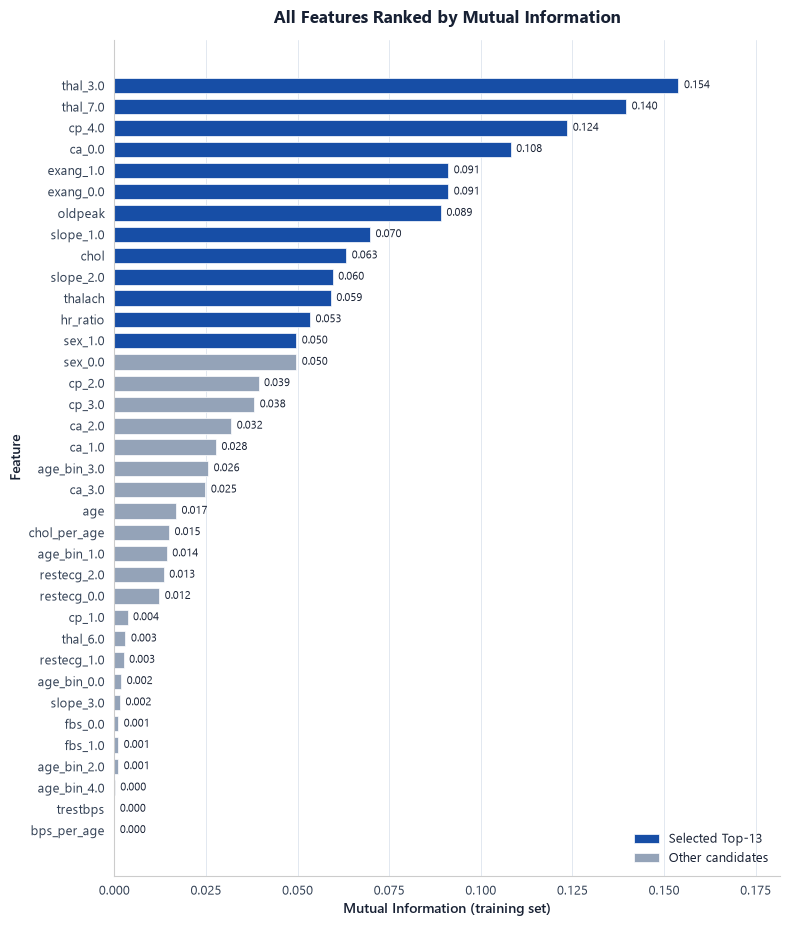

In [10]:
# Visualize every encoded feature, including all age-based candidates.
fe_all_features = fe_mi_ranking.copy()
with sns.axes_style("whitegrid"), plt.rc_context(plot_style):
    fig, ax = plt.subplots(figsize=(8, max(6, 0.26 * len(fe_all_features))))
    positions = np.arange(len(fe_all_features))
    for selected, color, label in [(True, "#174EA6", f"Selected Top-{fe_k}"),
                                    (False, "#94A3B8", "Other candidates")]:
        mask = fe_all_features["selected_top_k"].to_numpy() == selected
        bars = ax.barh(positions[mask], fe_all_features.loc[mask, "mutual_information"],
                       color=color, height=0.72, edgecolor="white", linewidth=0.5,
                       label=label)
        ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=8, color="#172033")
    ax.set_yticks(positions, fe_all_features["feature"])
    ax.invert_yaxis()
    ax.set_title("All Features Ranked by Mutual Information", pad=12, fontsize=12)
    ax.set_xlabel("Mutual Information (training set)", fontsize=10)
    ax.set_ylabel("Feature", fontsize=10)
    ax.tick_params(axis="both", labelsize=9)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.margins(x=0.18)
    ax.legend(loc="lower right", fontsize=9, frameon=False)
    fig.tight_layout()
    plt.show()
